# 02 — Image features, classifier training, and confidence checks
**Goal:** give our picture learner a working pair of eyes, teach it a small set of picture names, and check its predictions.

Run Notebooks 00 and 01 first. Then run these cells from top to bottom. The first run downloads CIFAR-10 (about 163 MiB) and ResNet-18 weights (about 45 MiB), and computes image features. Later runs reuse the saved features.

**Our simple approach:** picture → frozen ResNet-18 → 512 numbers → small classifier. *Frozen* means we never change ResNet-18's existing weights. Only the small final classifier learns.

**This is a clean-label development check**, not a fatigue experiment or final result. We use known picture names to check the machinery before adding simulated human errors. Final-test images are excluded from feature extraction, training, predictions, and plots.

Sources: [CIFAR-10H image ordering](https://github.com/jcpeterson/cifar-10h),
[torchvision CIFAR-10 loader](https://docs.pytorch.org/vision/0.23/generated/torchvision.datasets.CIFAR10.html),
[ResNet-18 weights and preprocessing](https://docs.pytorch.org/vision/0.23/models/generated/torchvision.models.resnet18.html).

## 1. Load the tools
Use the project's `.venv/bin/python` interpreter as the notebook kernel. If PyTorch is missing in another environment, install the packages from `requirements.txt` into that environment and restart its kernel. `torch` trains the small classifier; `torchvision` supplies pictures and ResNet-18.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.datasets import CIFAR10
from torchvision.models import resnet18, ResNet18_Weights
from IPython.display import display

project = Path.cwd()
if project.name == 'notebooks':
    project = project.parent
settings = json.loads((project / 'configs/project_settings.json').read_text())
seed = settings['seed']
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(4)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False})

## 2. Save the notebook settings
An **epoch** is one pass over the labelled pictures. A **learning rate** controls how big a training adjustment is. These are fixed starting settings, not tuned on the final test. The 50- and 200-picture sizes match the brief. The 500- and 1,000-picture sizes show how the learner's confidence changes as more correct labels become available. Results are grouped by a short settings fingerprint and seed so we can trace each run.

In [2]:
options = {'seed': seed, 'label_counts': [50, 200, 500, 1000], 'epochs': 200,
           'learning_rate': 0.05, 'weight_decay': 0.01, 'batch_size': 64,
           'weights': 'ResNet18_Weights.IMAGENET1K_V1', 'feature_normalization': 'L2',
           'acquisition': 'nested random order, clean ground-truth labels'}
options['image_split_sha256'] = hashlib.sha256((project / 'data/splits/images.csv').read_bytes()).hexdigest()
run_hash = hashlib.sha256(json.dumps(options, sort_keys=True).encode()).hexdigest()[:10]
output_folder = project / 'outputs/classifier_development' / run_hash / f'seed-{seed}'
feature_folder = project / 'data/features'
output_folder.mkdir(parents=True, exist_ok=True)
feature_folder.mkdir(parents=True, exist_ok=True)
(project / 'configs/classifier_settings.json').write_text(json.dumps(options, indent=2))
display(pd.Series(options, name='value').to_frame())

def show_plot(name):
    plt.tight_layout()
    plt.savefig(output_folder / f'{name}.png', dpi=150)
    plt.show()
print('Results folder:', output_folder)

,value
seed,42
label_counts,"[50, 200, 500, 1000]"
epochs,200
learning_rate,0.05
weight_decay,0.01
batch_size,64
weights,ResNet18_Weights.IMAGENET1K_V1
feature_normalization,L2
acquisition,"nested random order, clean ground-truth labels"
image_split_sha256,69b06484395291f470cdfc12ad7102bb059215866f09b0...


Results folder: /Users/shaikha/MLProjects/advanced_ml/outputs/classifier_development/275ecd4172/seed-42


## 3. Match actual pictures to the saved image IDs
CIFAR-10H uses the original CIFAR-10 **test collection**, so `train=False` loads the correct 10,000-image collection. We still follow our own saved pool/validation/test split. The dataset loader downloads the full archive, but our model only processes development IDs. Checking category metadata for alignment is not a classifier evaluation.

In [3]:
image_split = pd.read_csv(project / 'data/splits/images.csv').sort_values('image_id')
pictures = CIFAR10(root=str(project / 'data/cifar10'), train=False, download=True)
labels = np.array(pictures.targets)
class_names = pictures.classes
assert np.array_equal(image_split['image_id'], np.arange(len(pictures)))
assert np.array_equal(image_split['true_label'], labels)
assert image_split['true_category'].tolist() == [class_names[label] for label in labels]
development_ids = image_split.loc[image_split['image_split'] != 'final_test', 'image_id'].to_numpy()
pool_ids = image_split.loc[image_split['image_split'] == 'pool', 'image_id'].to_numpy()
final_test_ids = image_split.loc[image_split['image_split'] == 'final_test', 'image_id'].to_numpy()
assert len(development_ids) == 8000 and len(pool_ids) == 4000
assert not np.isin(development_ids, final_test_ids).any()
print('Category and ID alignment passed. We will process 8,000 development images only.')

100.0%


Category and ID alignment passed. We will process 8,000 development images only.


## 4. Look at the actual pictures
Each row shows two pool pictures from each category. They really are only 32 × 32 pixels. Some are blurry, which helps explain why people and classifiers can disagree.

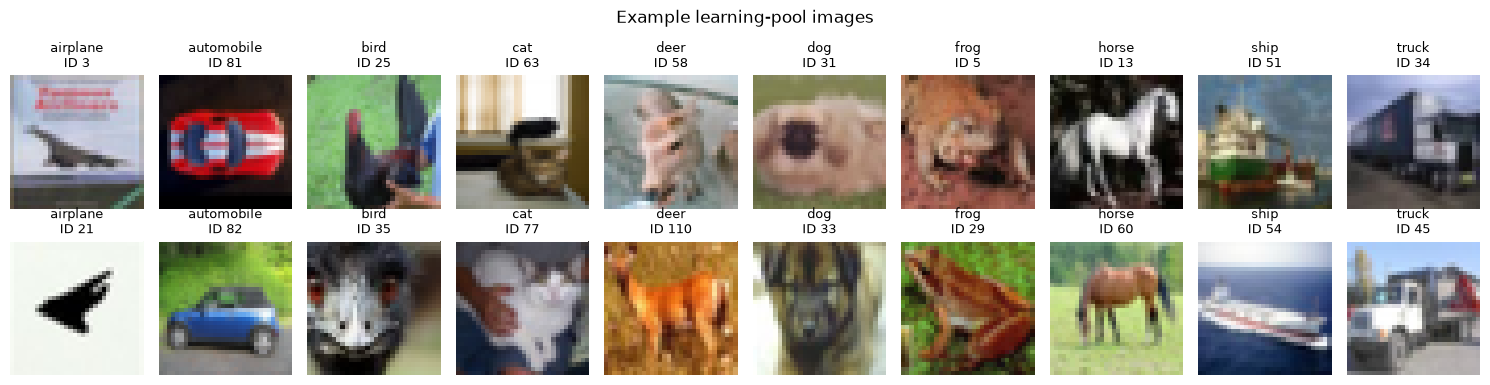

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(15, 4))
example_ids = []
for class_id, class_name in enumerate(class_names):
    chosen_ids = pool_ids[labels[pool_ids] == class_id][:2]
    example_ids.extend(chosen_ids)
    for row, image_id in enumerate(chosen_ids):
        axes[row, class_id].imshow(pictures.data[image_id])
        axes[row, class_id].set_title(f'{class_name}\nID {image_id}', fontsize=9)
        axes[row, class_id].axis('off')
fig.suptitle('Example learning-pool images')
show_plot('01_example_pictures')

## 5. Load the frozen picture reader
ResNet-18 was trained on ImageNet, a large picture collection. We remove its old 1,000-category answer layer and keep its 512-number image description. `.eval()` keeps its behaviour fixed. Turning gradients off prevents training it. CUDA or Apple MPS speeds up extraction when available; the CPU also works.

In [5]:
device = 'cpu'
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
torch.hub.set_dir(str(project / 'data/pretrained'))
weights = ResNet18_Weights.IMAGENET1K_V1
preprocess = weights.transforms()
picture_reader = resnet18(weights=weights)
picture_reader.fc = nn.Identity()
picture_reader.requires_grad_(False)
picture_reader.eval().to(device)
print('Feature extraction device:', device)
print('Trainable parameters in picture reader:', sum(p.numel() for p in picture_reader.parameters() if p.requires_grad))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /Users/shaikha/MLProjects/advanced_ml/data/pretrained/checkpoints/resnet18-f37072fd.pth


100.0%


Feature extraction device: mps
Trainable parameters in picture reader: 0


## 6. See what preprocessing does
We resize and center-crop pictures to the pretrained model's expected 224 × 224 size, then normalize their colours using its supplied settings. Enlarging a picture does not add missing detail. The displayed processed image has colour normalization undone so that it looks natural to our eyes.

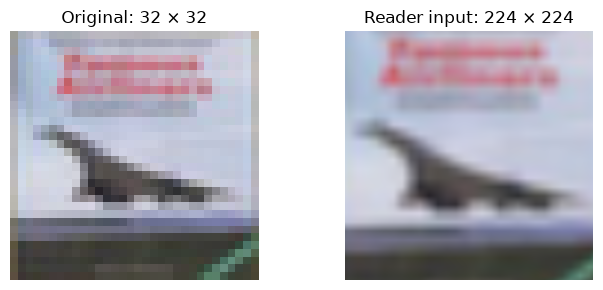

In [6]:
example_id = example_ids[0]
original = torch.from_numpy(pictures.data[example_id]).permute(2, 0, 1).float() / 255
processed = preprocess(original)
colour_mean = torch.tensor(preprocess.mean)[:, None, None]
colour_std = torch.tensor(preprocess.std)[:, None, None]
visible_processed = (processed * colour_std + colour_mean).clamp(0, 1)
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
axes[0].imshow(pictures.data[example_id])
axes[0].set_title('Original: 32 × 32')
axes[1].imshow(visible_processed.permute(1, 2, 0))
axes[1].set_title('Reader input: 224 × 224')
for ax in axes:
    ax.axis('off')
show_plot('02_image_preprocessing')

## 7. Extract and save features
For each development picture, save its ID and its 512-number description. A **batch** is just a small group processed together. No final-test picture enters this loop. This is the slowest step; later runs load the saved file. A fingerprint detects a changed split.

In [7]:
feature_path = feature_folder / 'resnet18_development_features.npz'
feature_metadata_path = feature_folder / 'resnet18_development_metadata.json'
feature_metadata = {'weights': options['weights'], 'preprocessing': str(preprocess),
    'image_split_sha256': hashlib.sha256((project / 'data/splits/images.csv').read_bytes()).hexdigest()}
if feature_path.exists():
    assert json.loads(feature_metadata_path.read_text()) == feature_metadata, 'Feature settings changed; rebuild the cache deliberately.'
    with np.load(feature_path) as saved:
        assert np.array_equal(saved['image_ids'], development_ids)
        feature_values = saved['features'].copy()
    print('Loaded saved features.')
else:
    feature_batches = []
    with torch.inference_mode():
        for start in range(0, len(development_ids), options['batch_size']):
            batch_ids = development_ids[start:start + options['batch_size']]
            images = torch.from_numpy(pictures.data[batch_ids]).permute(0, 3, 1, 2).float() / 255
            feature_batches.append(picture_reader(preprocess(images).to(device)).cpu().numpy())
            if start % (options['batch_size'] * 20) == 0:
                print(f'Processed {min(start + len(batch_ids), len(development_ids)):,} / {len(development_ids):,} pictures')
    feature_values = np.concatenate(feature_batches)
    np.savez_compressed(feature_path, image_ids=development_ids, features=feature_values)
    feature_metadata_path.write_text(json.dumps(feature_metadata, indent=2))
assert feature_values.shape == (8000, 512) and np.isfinite(feature_values).all()
print('Feature table shape:', feature_values.shape)

Processed 64 / 8,000 pictures
Processed 1,344 / 8,000 pictures
Processed 2,624 / 8,000 pictures
Processed 3,904 / 8,000 pictures
Processed 5,184 / 8,000 pictures
Processed 6,464 / 8,000 pictures
Processed 7,744 / 8,000 pictures
Feature table shape: (8000, 512)


## 8. Inspect the features
Rows below are pictures and columns are the first 40 feature numbers. These numbers describe visual patterns; individual columns do not have simple names like "cat ear." We normalize each full feature row to length 1 before training, so large feature magnitudes do not dominate. The raw feature cache is kept for later notebooks.

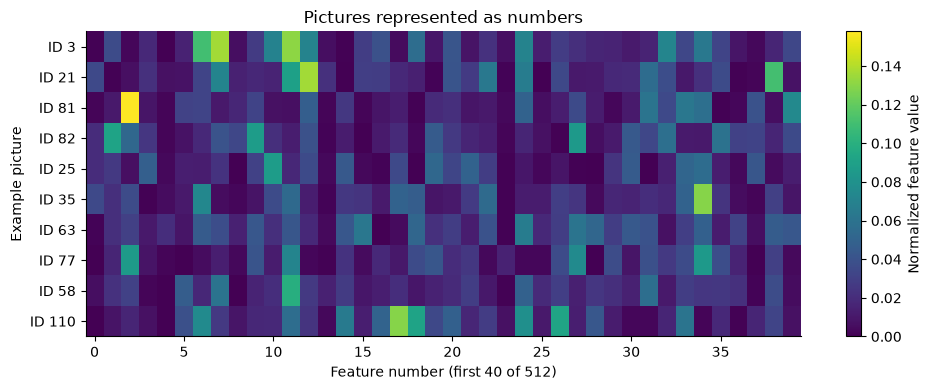

In [9]:
features = F.normalize(torch.from_numpy(feature_values.copy()), dim=1)
row_for_image = pd.Series(np.arange(len(development_ids)), index=development_ids)
first_rows = row_for_image.loc[example_ids[:10]].to_numpy()
plt.figure(figsize=(10, 4))
plt.imshow(features[first_rows, :40], aspect='auto', cmap='viridis')
plt.colorbar(label='Normalized feature value')
plt.yticks(range(10), [f'ID {image_id}' for image_id in example_ids[:10]])
plt.xlabel('Feature number (first 40 of 512)')
plt.ylabel('Example picture')
plt.title('Pictures represented as numbers')
show_plot('03_image_feature_heatmap')

## 9. Give validation images two separate jobs
We divide the 2,000 validation images equally, keeping 100 of each category in each half. **Calibration images** adjust confidence. **Evaluation images** check accuracy and confidence on different pictures. Neither half trains the classifier's weights. This remains development evaluation, not our final test.

In [10]:
validation_images = image_split[image_split['image_split'] == 'validation']
random = np.random.default_rng(seed)
validation_groups = []
for class_id, group in validation_images.groupby('true_label'):
    ids = random.permutation(group['image_id'].to_numpy())
    validation_groups.append(pd.DataFrame({'image_id': ids,
        'validation_role': ['calibration'] * 100 + ['evaluation'] * 100}))
validation_roles = pd.concat(validation_groups).sort_values('image_id').reset_index(drop=True)
roles_path = project / 'data/splits/validation_roles.csv'
if roles_path.exists():
    pd.testing.assert_frame_equal(pd.read_csv(roles_path), validation_roles)
else:
    validation_roles.to_csv(roles_path, index=False)
calibration_ids = validation_roles.loc[validation_roles['validation_role'] == 'calibration', 'image_id'].to_numpy()
evaluation_ids = validation_roles.loc[validation_roles['validation_role'] == 'evaluation', 'image_id'].to_numpy()
assert not np.isin(calibration_ids, evaluation_ids).any()
assert not np.isin(pool_ids, np.r_[calibration_ids, evaluation_ids, final_test_ids]).any()
display(validation_roles['validation_role'].value_counts().to_frame('images'))

,images
validation_role,
evaluation,1000
calibration,1000


## 10. Build the small classifier
A **linear head** gives each of the 10 categories a score from the 512 input features. **Cross-entropy loss** is the training penalty for giving the true category a low probability. The optimizer changes the head to reduce that penalty. We keep this small training job on the CPU, even if a GPU was used to extract features.

In [11]:
def train_classifier(image_ids):
    torch.manual_seed(seed)
    head = nn.Linear(512, 10)
    optimizer = torch.optim.AdamW(head.parameters(), lr=options['learning_rate'], weight_decay=options['weight_decay'])
    train_features = features[row_for_image.loc[image_ids].to_numpy()]
    train_labels = torch.tensor(labels[image_ids], dtype=torch.long)
    losses = []
    for epoch in range(options['epochs']):
        optimizer.zero_grad()
        loss = F.cross_entropy(head(train_features), train_labels)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    head.eval()
    return head, losses

def predict_scores(head, image_ids):
    with torch.no_grad():
        return head(features[row_for_image.loc[image_ids].to_numpy()])

## 11. Adjust confidence with temperature scaling
A prediction can be right while its confidence is exaggerated. **Temperature** softens or sharpens probabilities without changing the top predicted category. We try a small grid of positive temperatures and choose the lowest calibration loss. A temperature above 1 softens predictions; below 1 sharpens them. Only the calibration half chooses this number. Better evaluation calibration is not guaranteed.

In [12]:
temperature_grid = torch.logspace(-1, 1, 81)

def calibrate_temperature(calibration_scores, calibration_labels):
    losses = [F.cross_entropy(calibration_scores / value, calibration_labels).item() for value in temperature_grid]
    best_index = int(np.argmin(losses))
    assert 0 < best_index < len(temperature_grid) - 1, 'Best temperature is at a boundary; expand the grid.'
    return float(temperature_grid[best_index]), losses

def prediction_metrics(scores, true_labels, temperature):
    probabilities = (scores / temperature).softmax(dim=1)
    correct = probabilities.argmax(dim=1).eq(true_labels)
    return {'accuracy_percent': correct.float().mean().item() * 100,
            'mean_confidence_percent': probabilities.max(dim=1).values.mean().item() * 100,
            'log_loss': F.cross_entropy(scores / temperature, true_labels).item()}

## 12. Run a small clean-label learning experiment
Use one random pool ordering. The 50-picture set is inside the 200-picture set, which is inside the 500-picture set, and so on. This is **nested random acquisition**. We retrain a fresh head at each checkpoint so this check is easy to reproduce.

This is not the later active-learning policy comparison and has no human-time budget. Saved confidence snapshots describe predictions on the **remaining unlabelled pool**. They will supply realistic confidence values to the fast simulator later.

In [13]:
pool_order = np.random.default_rng(seed).permutation(pool_ids)
np.save(output_folder / 'random_pool_order.npy', pool_order)
calibration_labels = torch.tensor(labels[calibration_ids], dtype=torch.long)
evaluation_labels = torch.tensor(labels[evaluation_ids], dtype=torch.long)
results, training_curves, temperature_curves = [], {}, {}
for label_count in options['label_counts']:
    acquired_ids = pool_order[:label_count]
    head, training_curves[label_count] = train_classifier(acquired_ids)
    calibration_scores = predict_scores(head, calibration_ids)
    temperature, temperature_curves[label_count] = calibrate_temperature(calibration_scores, calibration_labels)
    evaluation_scores = predict_scores(head, evaluation_ids)
    for version, value in [('Before calibration', 1.0), ('After calibration', temperature)]:
        results.append({'labels': label_count, 'version': version, 'temperature': value,
            **prediction_metrics(evaluation_scores, evaluation_labels, value)})
    remaining_ids = pool_order[label_count:]
    remaining_scores = predict_scores(head, remaining_ids)
    np.savez_compressed(output_folder / f'pool_confidence_{label_count}_labels.npz',
        image_ids=remaining_ids, probabilities=(remaining_scores / temperature).softmax(dim=1).numpy(),
        labelled_ids=acquired_ids, temperature=temperature)
    torch.save({'state_dict': head.state_dict(), 'temperature': temperature,
        'labelled_ids': acquired_ids.tolist(), 'options': options}, output_folder / f'classifier_{label_count}_labels.pt')
    print(f'{label_count} labels: temperature = {temperature:.2f}')
results = pd.DataFrame(results)
results.to_csv(output_folder / 'development_metrics.csv', index=False)
display(results.round(3))

50 labels: temperature = 2.11
200 labels: temperature = 1.19
500 labels: temperature = 1.26
1000 labels: temperature = 1.19


,labels,version,temperature,accuracy_percent,mean_confidence_percent,log_loss
0,50,Before calibration,1.000,53.5,69.563,2.030
1,50,After calibration,2.113,53.5,44.228,1.654
2,200,Before calibration,1.000,74.8,75.924,0.769
3,200,After calibration,1.189,74.8,71.237,0.770
4,500,Before calibration,1.000,77.2,80.983,0.694
5,500,After calibration,1.259,77.2,75.488,0.682
6,1000,Before calibration,1.000,79.2,82.395,0.637
7,1000,After calibration,1.189,79.2,78.658,0.626


## 13. Watch training and accuracy
The loss plot asks whether the head learned its training examples. The accuracy plot asks whether it recognizes **different** development pictures. One seed is only a pipeline check, so do not present this curve as a statistically established gain.

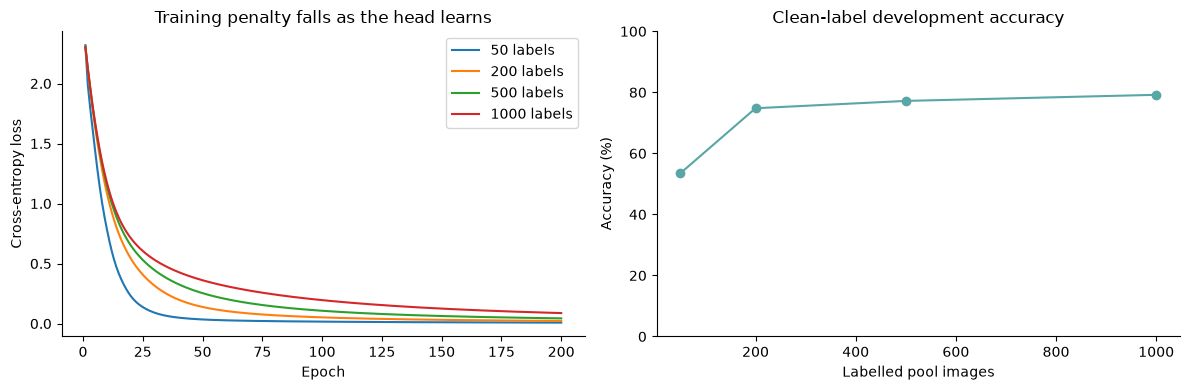

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label_count, losses in training_curves.items():
    axes[0].plot(range(1, len(losses) + 1), losses, label=f'{label_count} labels')
axes[0].set(title='Training penalty falls as the head learns', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend()
after = results[results['version'] == 'After calibration']
axes[1].plot(after['labels'], after['accuracy_percent'], 'o-', color='#58a6a6')
axes[1].set(title='Clean-label development accuracy', xlabel='Labelled pool images', ylabel='Accuracy (%)', ylim=(0, 100))
show_plot('04_training_and_development_accuracy')

## 14. See how temperature was chosen
The lowest point on each curve is the temperature selected using calibration pictures. The vertical dashed line means no temperature adjustment.

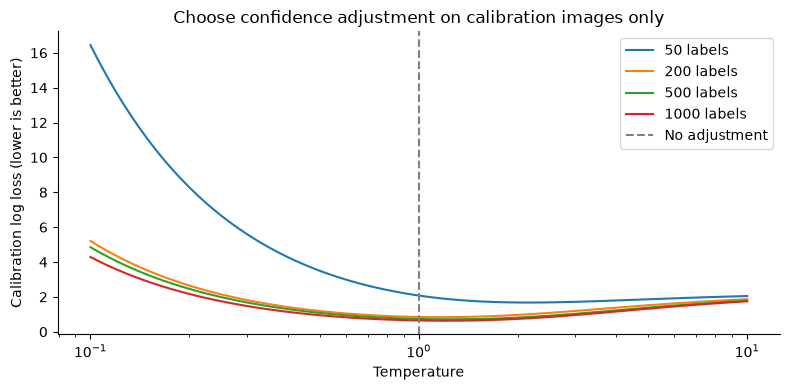

In [15]:
for label_count, losses in temperature_curves.items():
    plt.plot(temperature_grid.numpy(), losses, label=f'{label_count} labels')
plt.axvline(1, color='gray', linestyle='--', label='No adjustment')
plt.xscale('log')
plt.xlabel('Temperature')
plt.ylabel('Calibration log loss (lower is better)')
plt.title('Choose confidence adjustment on calibration images only')
plt.legend()
show_plot('05_temperature_selection')

## 15. Compare confidence with actual correctness
Use the final development checkpoint (1,000 labels). In a well-calibrated 80%-confidence group, roughly 80% of predictions should be correct. The diagonal shows that ideal. Empty bins are omitted; sparse bins are noisy. Counts underneath show how much evidence each bin has. This checks calibration on images that did not choose the temperature.

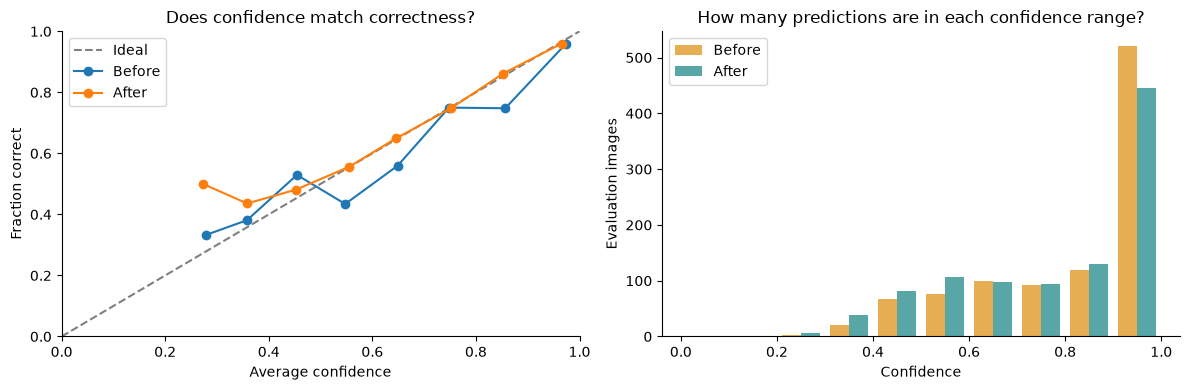

,confidence,accuracy,count
bin,,,
"(0.2, 0.3]",0.273,0.500,6
"(0.3, 0.4]",0.358,0.436,39
"(0.4, 0.5]",0.453,0.481,81
"(0.5, 0.6]",0.556,0.557,106
"(0.6, 0.7]",0.646,0.649,97
"(0.7, 0.8]",0.752,0.747,95
"(0.8, 0.9]",0.852,0.862,130
"(0.9, 1.0]",0.965,0.960,446


In [16]:
def confidence_bins(probabilities, true_labels):
    confidence, predicted = probabilities.max(dim=1)
    table = pd.DataFrame({'confidence': confidence.numpy(), 'correct': predicted.eq(true_labels).numpy()})
    table['bin'] = pd.cut(table['confidence'], bins=np.linspace(0, 1, 11), include_lowest=True)
    return table.groupby('bin', observed=True).agg(confidence=('confidence', 'mean'), accuracy=('correct', 'mean'), count=('correct', 'size'))

raw_probabilities = evaluation_scores.softmax(dim=1)
calibrated_probabilities = (evaluation_scores / temperature).softmax(dim=1)
raw_bins = confidence_bins(raw_probabilities, evaluation_labels)
calibrated_bins = confidence_bins(calibrated_probabilities, evaluation_labels)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Ideal')
for name, table in [('Before', raw_bins), ('After', calibrated_bins)]:
    axes[0].plot(table['confidence'], table['accuracy'], 'o-', label=name)
axes[0].set(title='Does confidence match correctness?', xlabel='Average confidence', ylabel='Fraction correct', xlim=(0, 1), ylim=(0, 1))
axes[0].legend()
axes[1].hist([raw_probabilities.max(1).values.numpy(), calibrated_probabilities.max(1).values.numpy()],
    bins=np.linspace(0, 1, 11), label=['Before', 'After'], color=['#e7ad52', '#58a6a6'])
axes[1].set(title='How many predictions are in each confidence range?', xlabel='Confidence', ylabel='Evaluation images')
axes[1].legend()
show_plot('06_confidence_reliability')
display(calibrated_bins.round(3))

## 16. Check calibration with numbers too
**Log loss** penalizes confident mistakes. **ECE** is the weighted gap between confidence and accuracy across the plotted bins. Lower is better for both, but ECE depends on bin choices. Temperature scaling leaves top-category accuracy unchanged.

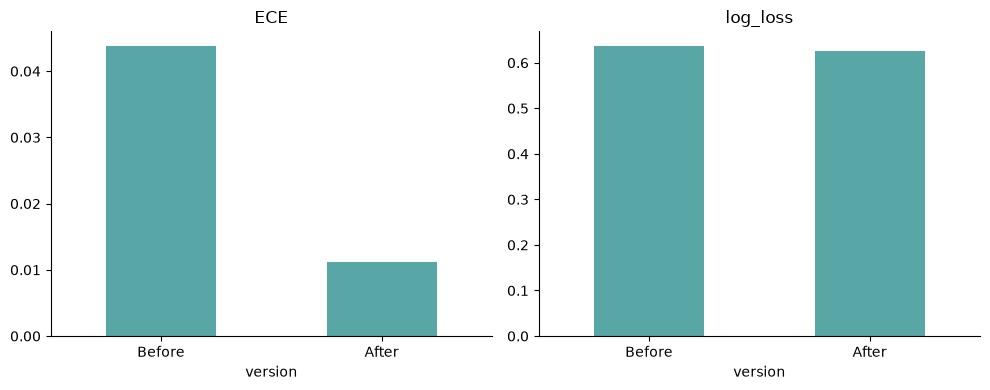

,ECE,log_loss
version,,
Before,0.0438,0.6371
After,0.0112,0.6257


In [17]:
calibration_comparison = []
for name, probabilities, table in [('Before', raw_probabilities, raw_bins), ('After', calibrated_probabilities, calibrated_bins)]:
    gap = (table['confidence'] - table['accuracy']).abs()
    calibration_comparison.append({'version': name, 'ECE': float((gap * table['count']).sum() / table['count'].sum()),
        'log_loss': float(-probabilities[torch.arange(len(evaluation_labels)), evaluation_labels].clamp_min(1e-12).log().mean())})
calibration_comparison = pd.DataFrame(calibration_comparison).set_index('version')
calibration_comparison.plot.bar(subplots=True, layout=(1, 2), figsize=(10, 4), legend=False, color='#58a6a6', rot=0)
show_plot('07_calibration_metrics')
display(calibration_comparison.round(4))
assert torch.equal(raw_probabilities.argmax(1), calibrated_probabilities.argmax(1))

## 17. Inspect category mistakes
Rows show the real category and columns show the predicted category. Values are percentages within each real category. This plot uses the 1,000-label classifier on evaluation images, not the human-answer records from Notebook 01.

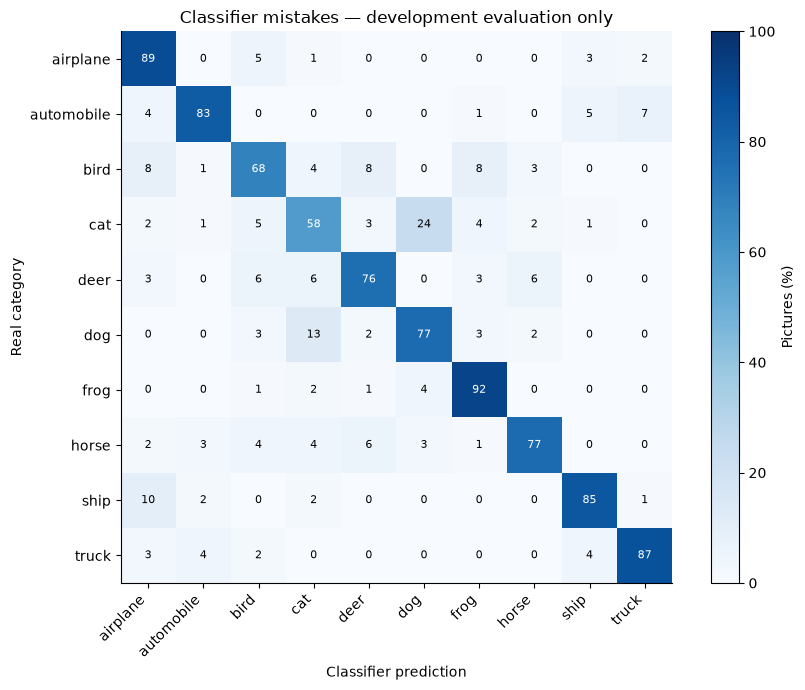

In [18]:
predicted_labels = calibrated_probabilities.argmax(dim=1).numpy()
confusion = pd.crosstab(pd.Series(labels[evaluation_ids], name='Real'),
    pd.Series(predicted_labels, name='Predicted'), normalize='index').reindex(index=range(10), columns=range(10), fill_value=0) * 100
fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(confusion, cmap='Blues', vmin=0, vmax=100)
ax.set_xticks(range(10), class_names, rotation=45, ha='right')
ax.set_yticks(range(10), class_names)
for row in range(10):
    for column in range(10):
        value = confusion.iloc[row, column]
        ax.text(column, row, f'{value:.0f}', ha='center', va='center', fontsize=8, color='white' if value > 50 else 'black')
ax.set(xlabel='Classifier prediction', ylabel='Real category', title='Classifier mistakes — development evaluation only')
fig.colorbar(image, ax=ax, label='Pictures (%)')
show_plot('08_classifier_confusion')

## 18. Look at actual predictions
Show up to five correct and five wrong predictions. Confidence belongs to the top prediction, not to the printed true category. Wrong predictions are useful examples, not a representative sample.

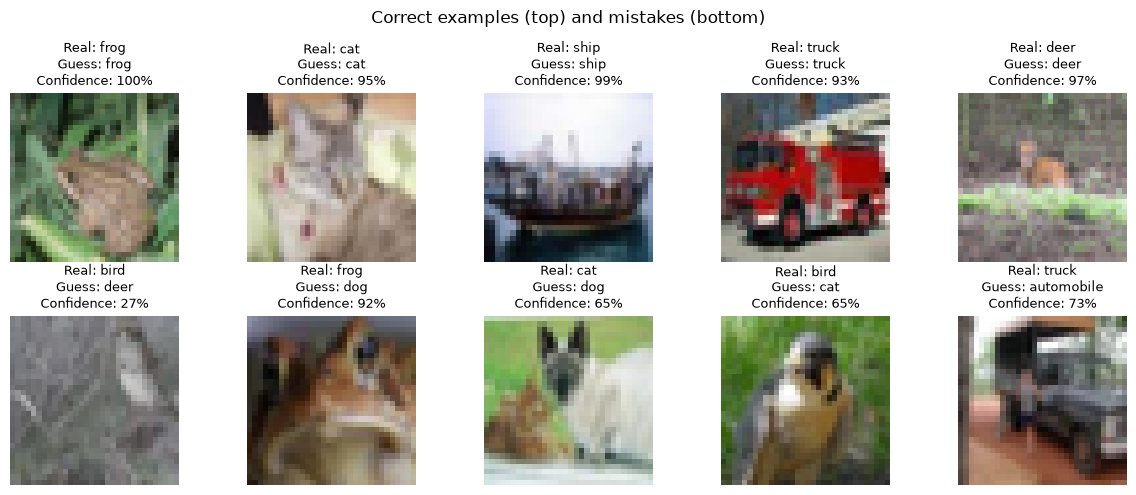

In [19]:
correct_mask = predicted_labels == labels[evaluation_ids]
correct_rows = np.flatnonzero(correct_mask)[:5]
wrong_rows = np.flatnonzero(~correct_mask)[:5]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax in axes.flat:
    ax.axis('off')
for row, selected_rows in enumerate([correct_rows, wrong_rows]):
    for column, position in enumerate(selected_rows):
        image_id = evaluation_ids[position]
        confidence = calibrated_probabilities[position].max().item() * 100
        axes[row, column].imshow(pictures.data[image_id])
        axes[row, column].set_title(f'Real: {class_names[labels[image_id]]}\nGuess: {class_names[predicted_labels[position]]}\nConfidence: {confidence:.0f}%', fontsize=9)
fig.suptitle('Correct examples (top) and mistakes (bottom)')
show_plot('09_example_predictions')

## 19. See how the remaining pool changes
As learning progresses, the model's probabilities may become sharper. **Entropy** measures uncertainty across all 10 categories: higher means less sure. Later, active learning uses entropy to find pictures worth asking about. These histograms describe the remaining pool at each checkpoint; the pool also shrinks.

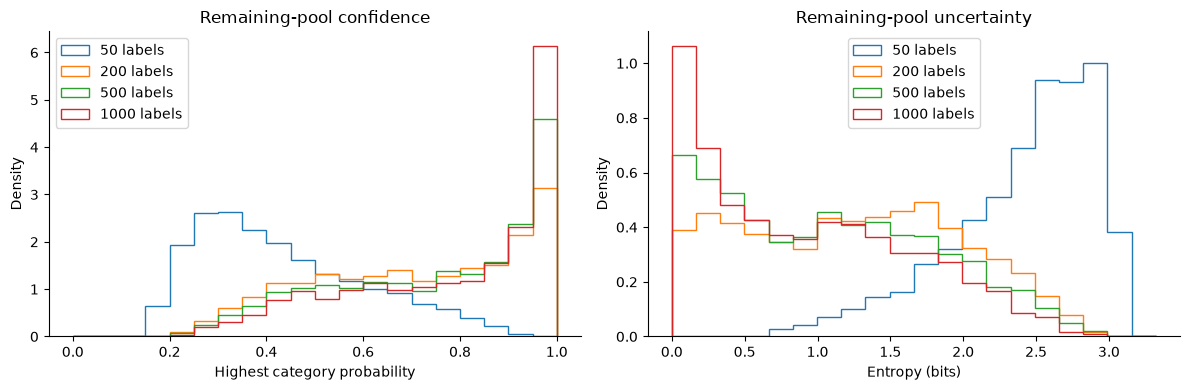

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label_count in options['label_counts']:
    with np.load(output_folder / f'pool_confidence_{label_count}_labels.npz') as snapshot:
        probabilities = snapshot['probabilities']
        assert np.allclose(probabilities.sum(axis=1), 1, atol=1e-6)
        assert not np.isin(snapshot['image_ids'], np.r_[snapshot['labelled_ids'], calibration_ids, evaluation_ids, final_test_ids]).any()
    entropy = -(probabilities * np.log2(probabilities.clip(1e-12))).sum(axis=1)
    axes[0].hist(probabilities.max(axis=1), bins=np.linspace(0, 1, 21), histtype='step', density=True, label=f'{label_count} labels')
    axes[1].hist(entropy, bins=np.linspace(0, np.log2(10), 21), histtype='step', density=True, label=f'{label_count} labels')
axes[0].set(title='Remaining-pool confidence', xlabel='Highest category probability', ylabel='Density')
axes[1].set(title='Remaining-pool uncertainty', xlabel='Entropy (bits)', ylabel='Density')
for ax in axes:
    ax.legend()
show_plot('10_pool_confidence_snapshots')

## 20. Save final checks and explain the result
We save one development prediction table plus enough settings to trace the run.
The snapshot files contain probabilities, not the true labels of the unlabelled pool.
Feature files use explicit image IDs; never assume their row number is the original image ID.

In [21]:
evaluation_predictions = pd.DataFrame({'image_id': evaluation_ids, 'true_label': labels[evaluation_ids],
    'predicted_label': predicted_labels, 'confidence': calibrated_probabilities.max(1).values.numpy()})
evaluation_predictions.to_csv(output_folder / 'evaluation_predictions_1000_labels.csv', index=False)
calibration_comparison.to_csv(output_folder / 'calibration_comparison.csv')
provenance = {'options': options, 'torch': torch.__version__, 'device_for_features': device,
    'feature_metadata': feature_metadata,
    'validation_roles_sha256': hashlib.sha256(roles_path.read_bytes()).hexdigest(),
    'final_test_evaluated': False, 'teacher': 'perfect clean labels; no fatigue',
    'training_curves': training_curves, 'temperature_curves': temperature_curves}
(output_folder / 'run_details.json').write_text(json.dumps(provenance, indent=2))
assert not picture_reader.training
assert all(not parameter.requires_grad for parameter in picture_reader.parameters())
assert not np.isin(evaluation_predictions['image_id'], final_test_ids).any()
print('Passed: frozen reader, finite features, disjoint splits, valid probabilities, and untouched final-test evaluation.')
print('Saved features, four classifiers, four confidence snapshots, metrics, and ten plot files.')

Passed: frozen reader, finite features, disjoint splits, valid probabilities, and untouched final-test evaluation.
Saved features, four classifiers, four confidence snapshots, metrics, and ten plot files.


## Summary:
1. We reused a pretrained image reader and kept it fixed.
2. Each development picture became 512 numbers, saved for reuse.
3. We trained only a small 10-category classifier, using nested sets of known pool labels.
4. We adjusted confidence on one validation half and checked it on the other half.
5. We saved realistic confidence distributions for the fast simulator.
6. We did not evaluate the reserved final-test images.

**Limits:** this is one clean-label development run. It does not establish fatigue benefits, human time savings, or a comparison against uncertainty sampling. Those need the later simulator, controllers, and repeated active-learning experiments. Calibration quality must be checked again as the classifier changes; this notebook does not guarantee all future predictions are calibrated.

**Next:** Notebook 03 — build and validate the simulated human teacher.